---
# <font color="#CA3532">Deep Learning Fundamentals and Basic Tools (2026/2027) - Final project</font>
---


In this project you will implement and compare four deep-learning architectures for multiclass human activity recognition:

- Deep Neural Network (DNN)
- Recurrent Neural Network (RNN)
- 1D Convolutional Neural Network (CNN)
- Long Short-Term Memory Network (LSTM)

You will work with the **UCI Human Activity Recognition Using Smartphones (UCI HAR)** dataset.

You must compare predictive performance, class-level errors, convergence, model complexity, training time, inference time, and stability across repeated runs.

## <font color="#3279ca">Generative-AI Policy</font>


The use of any generative-AI or Large Language Model (LLM) to generate, complete, rewrite, or substantially assist with the code, experiments, analysis, or written answers for this project is **not permitted**.

**Work generated using LLM assistance will be treated as plagiarism. If it is the case, the corresponding project code will not be evaluated and the student will receive no credit for that work.**


## <font color="#3279ca">Project report</font>

You must write a project report explaning the following points;

- individual functions and model layers;
- tensor dimensions;
- the training procedure;
- suugest an alternative for part of your implementation;
- interpret results, confusion matrices, and all metrics;
- explain your conclusions.

Do not submit code or analysis that you cannot explain.

### <font color="#0da432">Imports</font>

In [1]:
import json
import sys
import importlib
from pathlib import Path
from sklearn.model_selection import GroupShuffleSplit

if "src.models" in sys.modules:
    del sys.modules["src.models"]

import src.models
importlib.reload(src.models)
import time
import platform
from src.utils import set_seed
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder, StandardScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

import torch
from src.models import (
    DNNClassifier,
    RNNClassifier,
    CNNClassifier,
    LSTMClassifier,
)
from src.training import fit
from src.evaluation import (
    evaluate_model,
    count_parameters,
    measure_inference_time,
)

### <font color="#0da432">Dataset</font>

In [2]:
train_df = pd.read_csv("../data/final_project/train.csv")
test_df = pd.read_csv("../data/final_project/test.csv")

TARGET = "Activity"
DROP_COLUMNS = ["subject", TARGET]

X = train_df.drop(columns=DROP_COLUMNS).to_numpy(dtype=np.float32)
X_test = test_df.drop(columns=DROP_COLUMNS).to_numpy(dtype=np.float32)

label_encoder = LabelEncoder()

y = label_encoder.fit_transform(train_df[TARGET]).astype(np.int64)
y_test = label_encoder.transform(test_df[TARGET]).astype(np.int64)

class_names = label_encoder.classes_

# Create validation split from training data
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(X, y, groups=train_df["subject"])
)

X_train = X[train_idx]
X_val = X[val_idx]

y_train = y[train_idx]
y_val = y[val_idx]

# Verify subjects do not overlap
train_subjects = set(train_df.iloc[train_idx]["subject"])
val_subjects = set(train_df.iloc[val_idx]["subject"])

assert train_subjects.isdisjoint(val_subjects), \
    "Subject leakage detected!"

# Scale using ONLY training data
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train).astype(np.float32)
X_val = scaler.transform(X_val).astype(np.float32)
X_test = scaler.transform(X_test).astype(np.float32)

# Dataset dimensions
n_features = X_train.shape[1]
n_classes = len(class_names)

sequence_length = n_features

# DNN
X_train_dnn = X_train
X_val_dnn = X_val
X_test_dnn = X_test

# RNN / LSTM
# Shape: (samples, sequence_length, features_per_step)
X_train_rnn = X_train[..., np.newaxis]
X_val_rnn = X_val[..., np.newaxis]
X_test_rnn = X_test[..., np.newaxis]

X_train_lstm = X_train[..., np.newaxis]
X_val_lstm = X_val[..., np.newaxis]
X_test_lstm = X_test[..., np.newaxis]

# CNN - TensorFlow / Keras Conv1D
# Shape: (samples, length, channels)
X_train_cnn_tf = X_train[..., np.newaxis]
X_val_cnn_tf = X_val[..., np.newaxis]
X_test_cnn_tf = X_test[..., np.newaxis]

# CNN - PyTorch Conv1d
# Shape: (samples, channels, length)
X_train_cnn_torch = X_train[:, np.newaxis, :]
X_val_cnn_torch = X_val[:, np.newaxis, :]
X_test_cnn_torch = X_test[:, np.newaxis, :]

# Display dataset information
print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Test shape:", X_test.shape)

print("Number of features:", n_features)
print("Number of classes:", n_classes)

print("Training subjects:", len(train_subjects))
print("Validation subjects:", len(val_subjects))
print("Subject overlap:", len(train_subjects & val_subjects))

Training shape: (5551, 561)
Validation shape: (1801, 561)
Test shape: (2947, 561)
Number of features: 561
Number of classes: 6
Training subjects: 16
Validation subjects: 5
Subject overlap: 0


## <font color="#0da432">Implementation Requirements</font>
rgb(18, 13, 164)
You must implement the backend yourself.

Required files:

```text
src/models.py
src/training.py
src/evaluation.py
```

## `src/models.py`

Implement:

```python
DNNClassifier
RNNClassifier
CNNClassifier
LSTMClassifier
```

All models receive the same underlying information and must ultimately output:

```text
(batch_size, 6)
```

logits/scores.

### DNN

Transform:

```text
(batch, 561)
```

into an appropriate vector representation.

### RNN

Process the engineered feature positions sequentially with a vanilla recurrent architecture.

### CNN

Use one-dimensional convolution over the temporal dimension.

### LSTM

Use an LSTM-based sequence representation for classification.

Important architectural parameters should be configurable.

##  `src/training.py`

Implement:

```python
fit(
    model,
    X_train,
    y_train,
    X_val,
    y_val,
    **kwargs
)
```

It must return at least:

```python
{
    "model": ...,
    "history": {
        "train_loss": ...,
        "val_loss": ...,
        "train_accuracy": ...,
        "val_accuracy": ...
    },
    "training_time": ...,
    "epochs_completed": ...
}
```

Support appropriate training settings including epochs, batch size, learning rate, seed, device, and early stopping.

##  `src/evaluation.py`

Implement:

```python
evaluate_model(model, X, y, **kwargs)
count_parameters(model)
measure_inference_time(model, X, **kwargs)
```

`evaluate_model` must return at least:

```python
{
    "accuracy": ...,
    "macro_precision": ...,
    "macro_recall": ...,
    "macro_f1": ...,
    "weighted_f1": ...,
    "predictions": ...
}
```

##  `src/utils.py`

Implement:

```python
set_seed(seed)
```

The function must set the relevant random seeds for reproducibility.

# Instantiate DNN, RNN, CNN and LSTM

You may add additional keyword arguments supported by your implementation.

Document your final architecture choices.

In [3]:
SEED = 42
set_seed(SEED)

dnn_model = DNNClassifier(
    sequence_length=sequence_length,
    n_features=n_features,
    n_classes=n_classes
)

rnn_model = RNNClassifier(
    input_size=n_features,
    n_classes=n_classes,
)

cnn_model = CNNClassifier(
    input_size=n_features,
    n_classes=n_classes,
)

lstm_model = LSTMClassifier(
    input_size=n_features,
    n_classes=n_classes,
)

models = {
    "DNN": dnn_model,
    "RNN": rnn_model,
    "CNN": cnn_model,
    "LSTM": lstm_model,
}

# Forward-Pass

In [4]:
sample_batch = torch.tensor(
    X_train[:8],
    dtype=torch.float32,
)

for name, model in models.items():
    model.eval()

    with torch.no_grad():
        output = model(sample_batch)

    print(
        f"{name:5s} | "
        f"input={tuple(sample_batch.shape)} | "
        f"output={tuple(output.shape)}"
    )

    assert output.shape == (8, n_classes)

DNN   | input=(8, 561) | output=(8, 6)
RNN   | input=(8, 561) | output=(8, 6)
CNN   | input=(8, 561) | output=(8, 6)
LSTM  | input=(8, 561) | output=(8, 6)


### ⚠️ Architecture documentation 

For each architecture document:

- input representation;
- layer structure;
- hidden/filter dimensions;
- activation functions;
- dropout;
- output representation;
- parameter choices;
- what temporal information the architecture can exploit.

**TODO:** Write your architecture documentation in the project report.

# Training

Use comparable conditions.

Do not use the test set for model selection or hyperparameter tuning.

In [5]:
TRAINING_CONFIG = {
    "epochs": 50,
    "batch_size": 64,
    "learning_rate": 1e-3,
    "patience": 8,
    "seed": SEED,
}

# Train DNN

In [6]:
dnn_result = fit(
    dnn_model,
    X_train, y_train,
    X_val, y_val,
    **TRAINING_CONFIG,
)
dnn_model = dnn_result["model"]

print("Training time:", dnn_result["training_time"])
print("Epochs:", dnn_result["epochs_completed"])

Early stopping
Training time: 6.070528030395508
Epochs: 17


# Train RNN

In [7]:
rnn_result = fit(
    rnn_model,
    X_train, y_train,
    X_val, y_val,
    **TRAINING_CONFIG,
)

rnn_model = rnn_result["model"]

print("Training time:", rnn_result["training_time"])
print("Epochs:", rnn_result["epochs_completed"])

Early stopping
Training time: 348.6456370353699
Epochs: 19


# Train CNN

In [8]:
cnn_result = fit(
    cnn_model,
    X_train, y_train,
    X_val, y_val,
    **TRAINING_CONFIG,
)

cnn_model = cnn_result["model"]

print("Training time:", cnn_result["training_time"])
print("Epochs:", cnn_result["epochs_completed"])

Training time: 19.370940923690796
Epochs: 50


# Train LSTM

In [9]:
lstm_result = fit(
    lstm_model,
    X_train, y_train,
    X_val, y_val,
    **TRAINING_CONFIG,
)

lstm_model = lstm_result["model"]

print("Training time:", lstm_result["training_time"])
print("Epochs:", lstm_result["epochs_completed"])

Early stopping
Training time: 92.57733011245728
Epochs: 21


# Collect Training Results

In [10]:
training_results = {
    "DNN": dnn_result,
    "RNN": rnn_result,
    "CNN": cnn_result,
    "LSTM": lstm_result,
}

trained_models = {
    name: result["model"]
    for name, result in training_results.items()
}

# Loss Curves

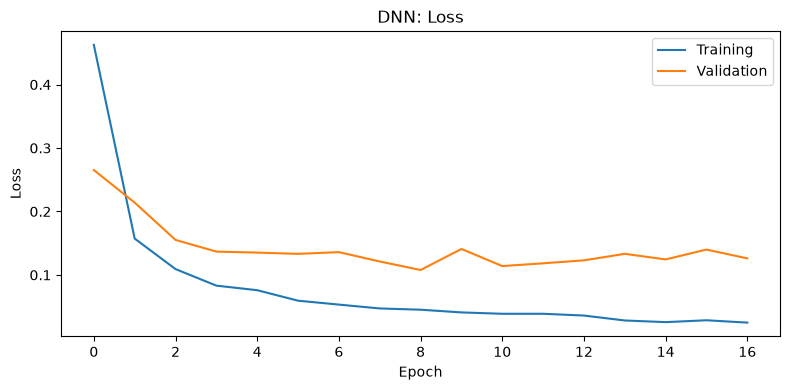

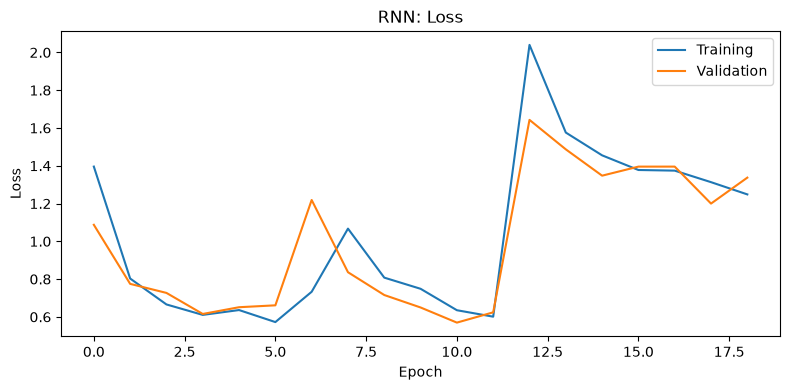

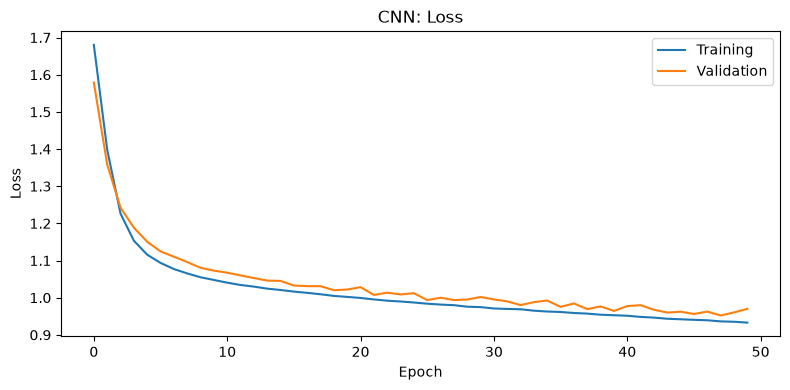

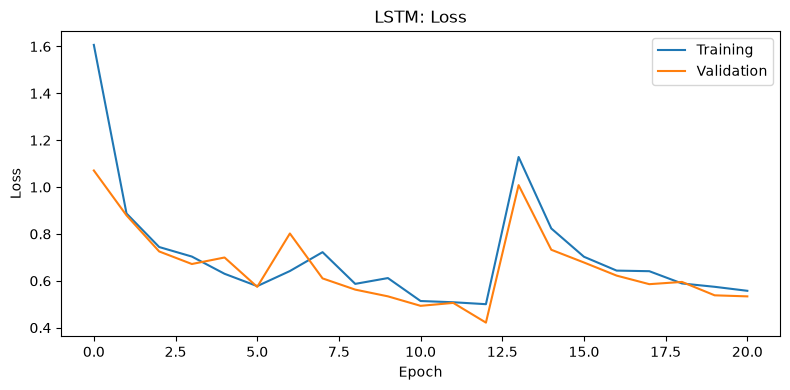

In [11]:
for name, result in training_results.items():
    history = result["history"]

    plt.figure(figsize=(8, 4))
    plt.plot(history["train_loss"], label="Training")
    plt.plot(history["val_loss"], label="Validation")
    plt.title(f"{name}: Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.tight_layout()
    plt.show()

#  Accuracy Curves

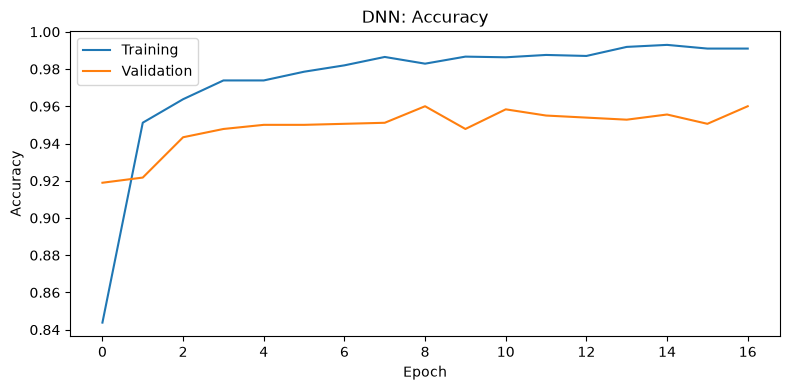

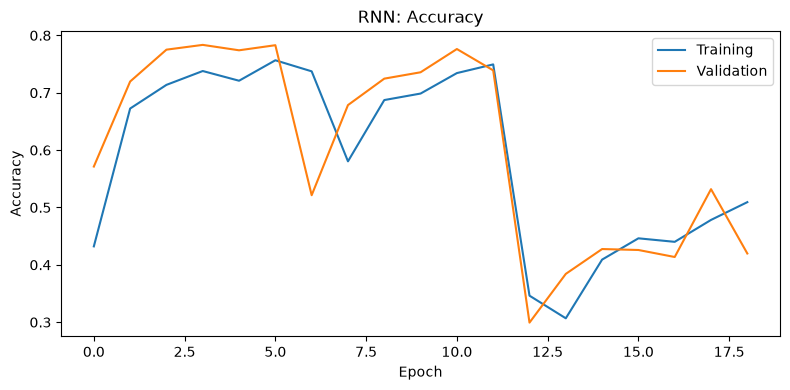

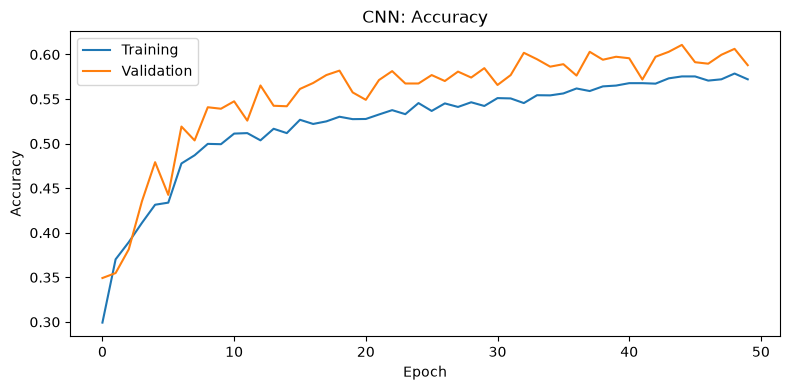

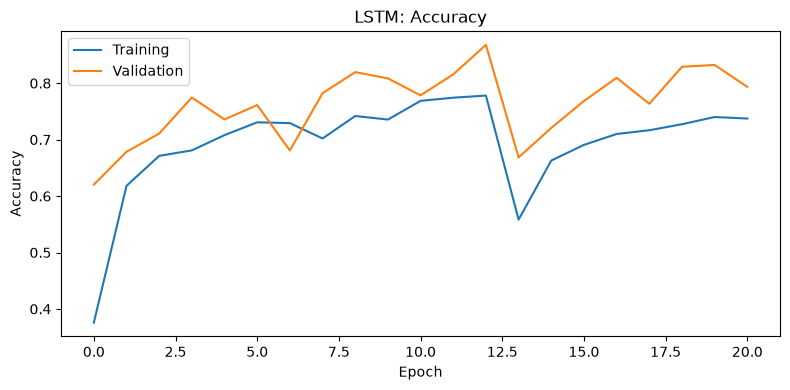

In [12]:
for name, result in training_results.items():
    history = result["history"]

    plt.figure(figsize=(8, 4))
    plt.plot(history["train_accuracy"], label="Training")
    plt.plot(history["val_accuracy"], label="Validation")
    plt.title(f"{name}: Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.tight_layout()
    plt.show()

### ⚠️ Training behavior analysis

For each architecture explain:

- convergence speed;
- overfitting;
- underfitting;
- stability;
- early stopping;
- train/validation gap.

**TODO:** Write add your analysis in ypur report.

# Final Test Evaluation



Report:

- Accuracy
- Macro Precision
- Macro Recall
- Macro F1
- Weighted F1
- Per-class metrics

In [13]:
test_results = {}

for name, model in trained_models.items():
    test_results[name] = evaluate_model(
        model,
        X_test,
        y_test,
    )

comparison_df = pd.DataFrame([
    {
        "Model": name,
        "Accuracy": result["accuracy"],
        "Macro Precision": result["macro_precision"],
        "Macro Recall": result["macro_recall"],
        "Macro F1": result["macro_f1"],
        "Weighted F1": result["weighted_f1"],
    }
    for name, result in test_results.items()
])

comparison_df

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,DNN,0.939939,0.942710,0.938400,0.939566,0.939959
1,RNN,0.697998,0.690134,0.686172,0.686521,0.697438
2,CNN,0.573465,0.577585,0.564923,0.536166,0.538859
3,LSTM,0.747540,0.753621,0.736029,0.740182,0.750839


# Per-Class Classification Reports

In [14]:
for name, result in test_results.items():
    print("\n" + "=" * 80)
    print(name)
    print("=" * 80)

    print(
        classification_report(
            y_test,
            result["predictions"],
            target_names=class_names,
            digits=4,
        )
    )


DNN
                    precision    recall  f1-score   support

            LAYING     1.0000    0.9777    0.9887       537
           SITTING     0.9461    0.8574    0.8996       491
          STANDING     0.8639    0.9549    0.9071       532
           WALKING     0.9493    0.9819    0.9653       496
WALKING_DOWNSTAIRS     0.9695    0.9095    0.9386       420
  WALKING_UPSTAIRS     0.9274    0.9490    0.9381       471

          accuracy                         0.9399      2947
         macro avg     0.9427    0.9384    0.9396      2947
      weighted avg     0.9420    0.9399    0.9400      2947


RNN
                    precision    recall  f1-score   support

            LAYING     0.9961    0.9497    0.9724       537
           SITTING     0.8319    0.7658    0.7975       491
          STANDING     0.6904    0.8008    0.7415       532
           WALKING     0.5537    0.5302    0.5417       496
WALKING_DOWNSTAIRS     0.4959    0.4357    0.4639       420
  WALKING_UPSTAIRS     0.5

# Confusion Matrices

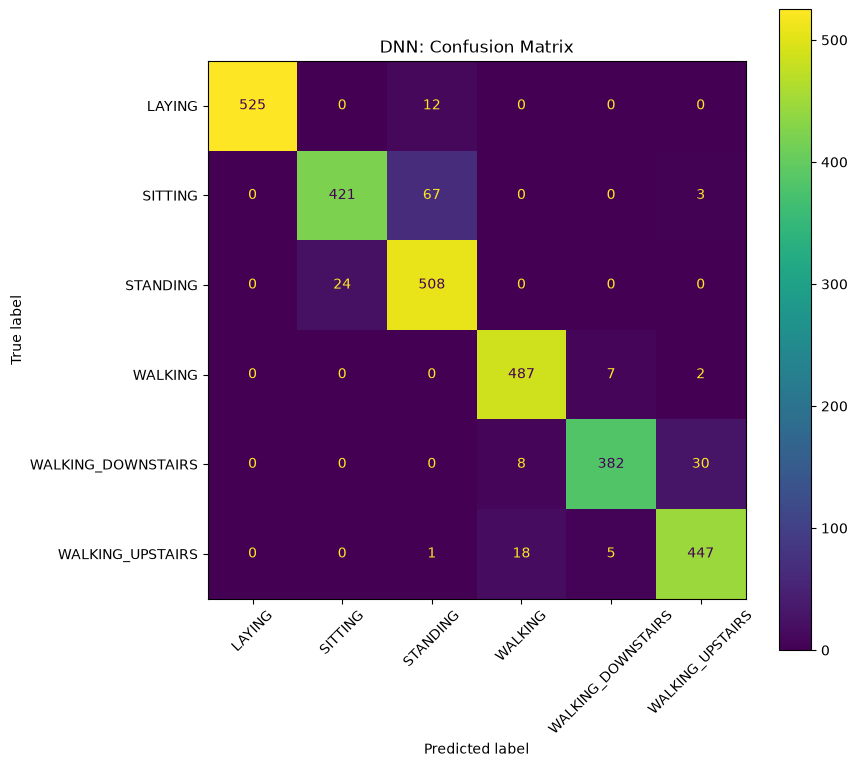

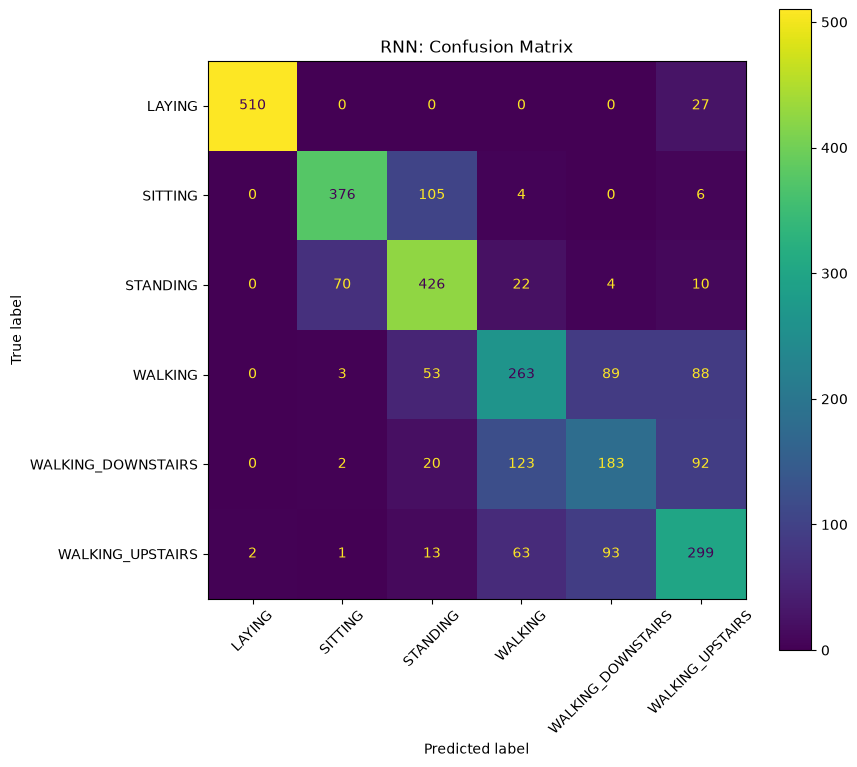

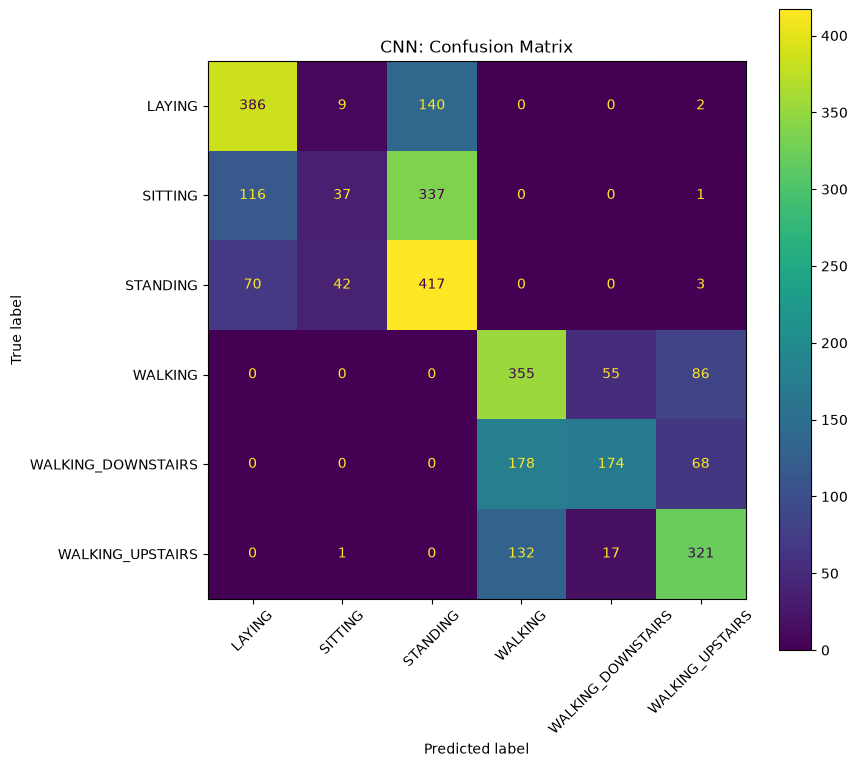

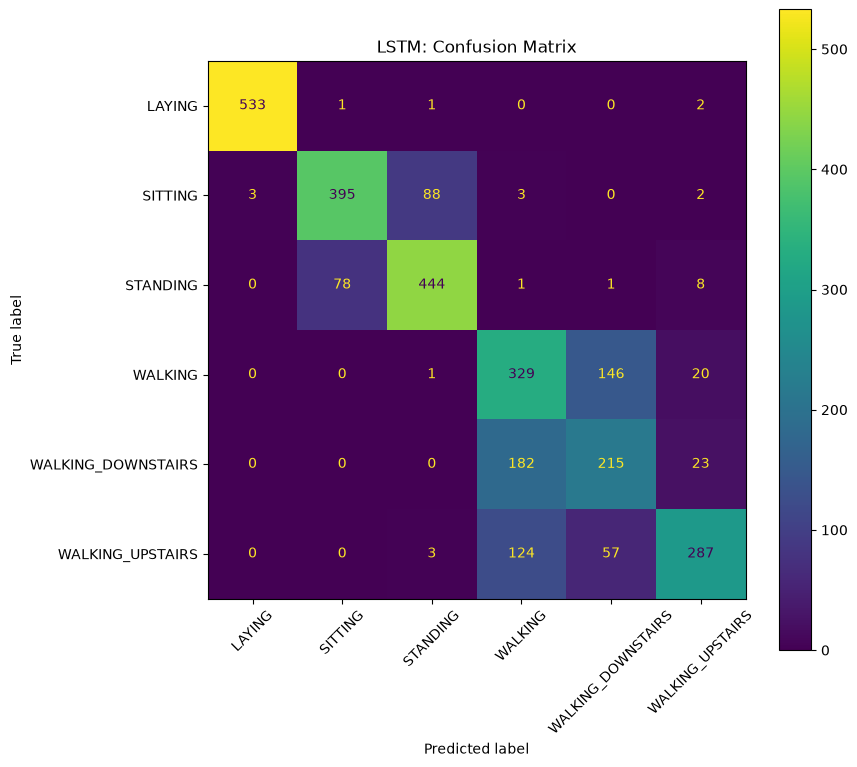

In [17]:
for name, result in test_results.items():
    cm = confusion_matrix(
        y_test,
        result["predictions"],
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_names,
    )

    fig, ax = plt.subplots(figsize=(9, 8))
    disp.plot(ax=ax, xticks_rotation=45)
    plt.title(f"{name}: Confusion Matrix")
    plt.tight_layout()
    plt.show()

### ⚠️ Activity-specific error analysis

Explain in ypur report:

- whether recurrent models make similar errors.
- whether CNN differs from RNN/LSTM.
- whether flattening disadvantages the DNN.


# Trainable Parameter Counts

In [18]:
parameter_counts = {
    name: count_parameters(model)
    for name, model in trained_models.items()
}

parameter_df = pd.DataFrame({
    "Model": list(parameter_counts.keys()),
    "Parameters": list(parameter_counts.values()),
})

parameter_df

,Model,Parameters
0,DNN,36358
1,RNN,4678
2,CNN,326
3,LSTM,17542


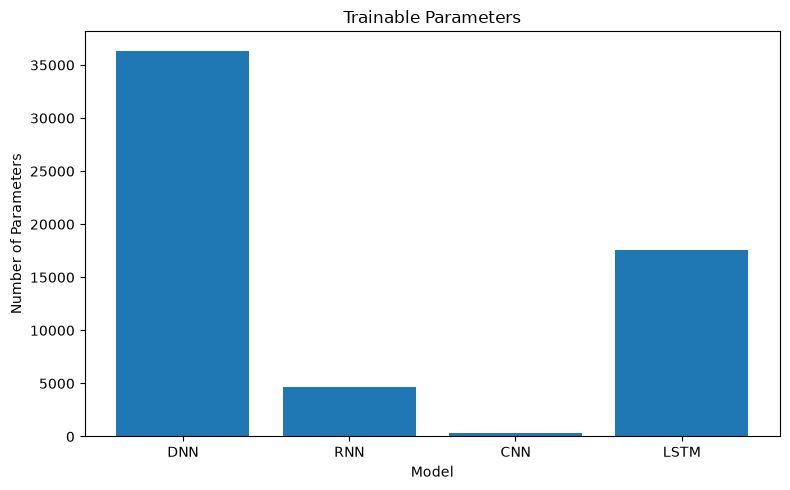

In [19]:
plt.figure(figsize=(8, 5))
plt.bar(parameter_df["Model"], parameter_df["Parameters"])
plt.title("Trainable Parameters")
plt.xlabel("Model")
plt.ylabel("Number of Parameters")
plt.tight_layout()
plt.show()

# Training-Time Comparison

In [20]:
training_time_df = pd.DataFrame([
    {
        "Model": name,
        "Training Time": result["training_time"],
        "Epochs": result["epochs_completed"],
        "Average Time / Epoch": (
            result["training_time"] /
            max(result["epochs_completed"], 1)
        ),
    }
    for name, result in training_results.items()
])

training_time_df

,Model,Training Time,Epochs,Average Time / Epoch
0,DNN,6.070528,17,0.357090
1,RNN,348.645637,19,18.349770
2,CNN,19.370941,50,0.387419
3,LSTM,92.577330,21,4.408444


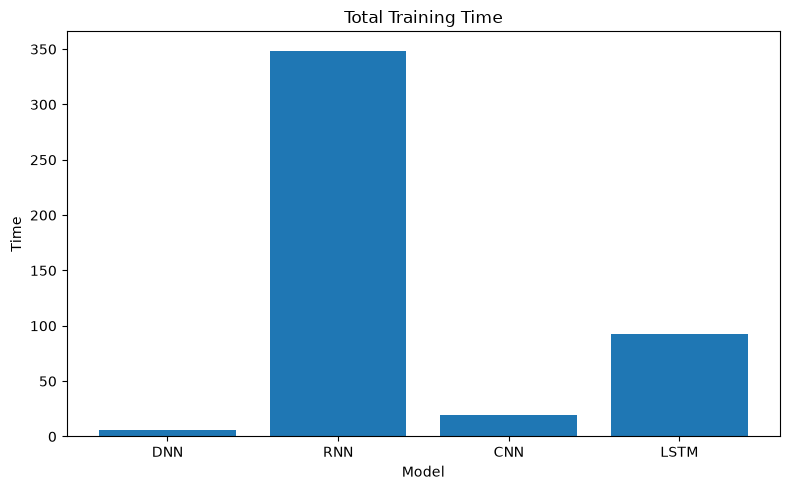

In [21]:
plt.figure(figsize=(8, 5))
plt.bar(
    training_time_df["Model"],
    training_time_df["Training Time"],
)
plt.title("Total Training Time")
plt.xlabel("Model")
plt.ylabel("Time")
plt.tight_layout()
plt.show()

# Inference-Time Comparison

In [22]:
inference_times = {
    name: measure_inference_time(model, X_test)
    for name, model in trained_models.items()
}

inference_df = pd.DataFrame({
    "Model": list(inference_times.keys()),
    "Inference Time": list(inference_times.values()),
})

inference_df

,Model,Inference Time
0,DNN,0.012222
1,RNN,0.990057
2,CNN,0.017612
3,LSTM,0.287284


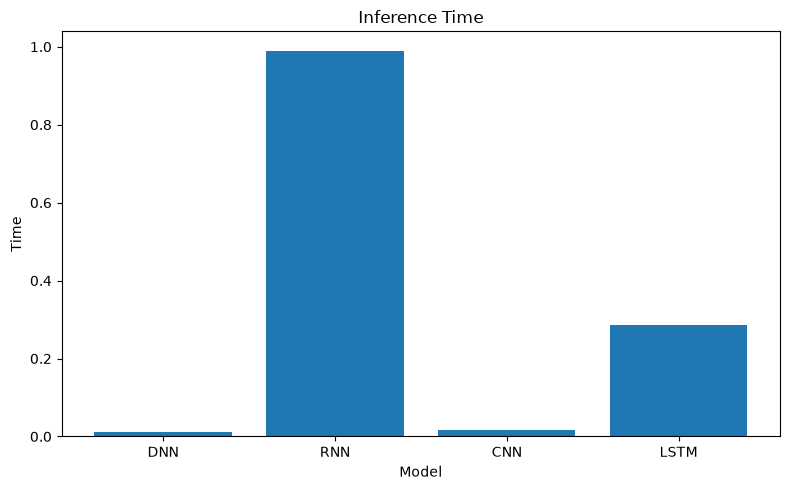

In [23]:
plt.figure(figsize=(8, 5))
plt.bar(
    inference_df["Model"],
    inference_df["Inference Time"],
)
plt.title("Inference Time")
plt.xlabel("Model")
plt.ylabel("Time")
plt.tight_layout()
plt.show()

# Complete Model Comparison

In [24]:
final_comparison = comparison_df.copy()

final_comparison["Parameters"] = (
    final_comparison["Model"].map(parameter_counts)
)

final_comparison["Training Time"] = (
    final_comparison["Model"].map({
        name: result["training_time"]
        for name, result in training_results.items()
    })
)

final_comparison["Inference Time"] = (
    final_comparison["Model"].map(inference_times)
)

final_comparison

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Parameters,Training Time,Inference Time
0,DNN,0.939939,0.942710,0.938400,0.939566,0.939959,36358,6.070528,0.012222
1,RNN,0.697998,0.690134,0.686172,0.686521,0.697438,4678,348.645637,0.990057
2,CNN,0.573465,0.577585,0.564923,0.536166,0.538859,326,19.370941,0.017612
3,LSTM,0.747540,0.753621,0.736029,0.740182,0.750839,17542,92.577330,0.287284


# Predictive-Metric Comparison

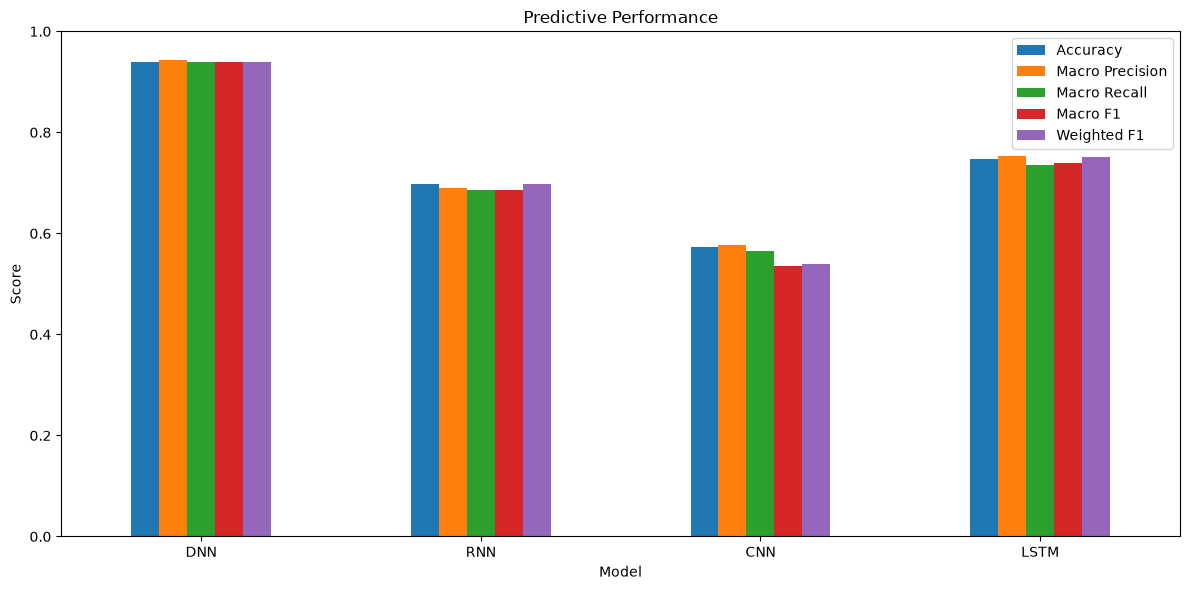

In [25]:
metric_columns = [
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1",
    "Weighted F1",
]

final_comparison.set_index("Model")[metric_columns].plot(
    kind="bar",
    figsize=(12, 6),
)

plt.title("Predictive Performance")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Performance vs Computational Cost

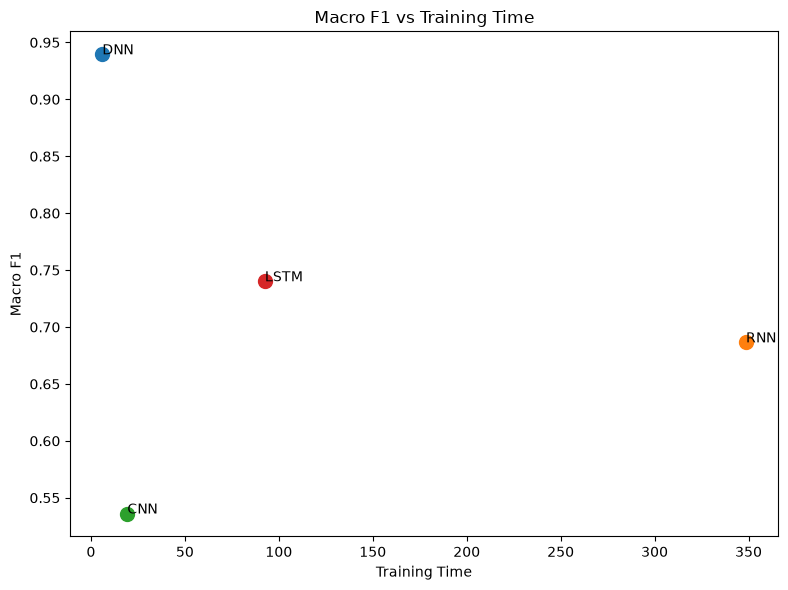

In [26]:
plt.figure(figsize=(8, 6))

for _, row in final_comparison.iterrows():
    plt.scatter(
        row["Training Time"],
        row["Macro F1"],
        s=100,
    )
    plt.annotate(
        row["Model"],
        (row["Training Time"], row["Macro F1"]),
    )

plt.xlabel("Training Time")
plt.ylabel("Macro F1")
plt.title("Macro F1 vs Training Time")
plt.tight_layout()
plt.show()

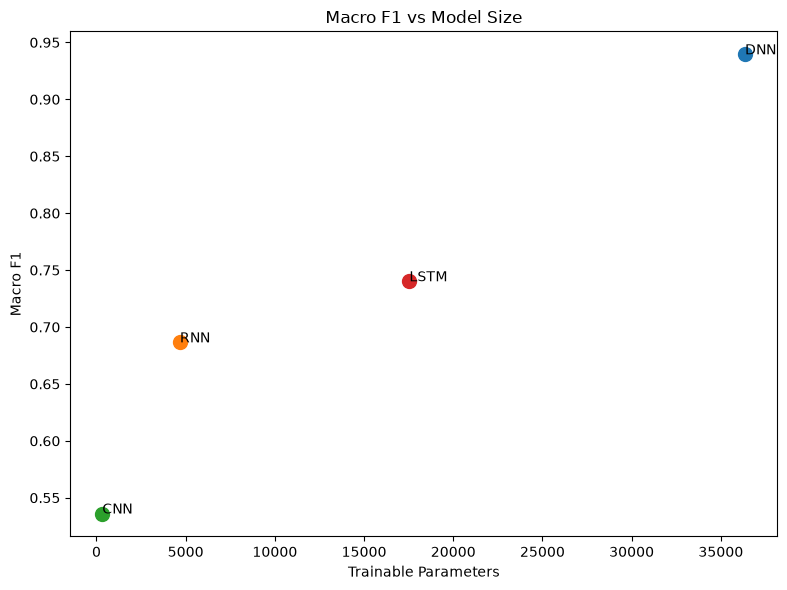

In [27]:
plt.figure(figsize=(8, 6))

for _, row in final_comparison.iterrows():
    plt.scatter(
        row["Parameters"],
        row["Macro F1"],
        s=100,
    )
    plt.annotate(
        row["Model"],
        (row["Parameters"], row["Macro F1"]),
    )

plt.xlabel("Trainable Parameters")
plt.ylabel("Macro F1")
plt.title("Macro F1 vs Model Size")
plt.tight_layout()
plt.show()

### ⚠️ Performance/cost discussion

Does increased architectural complexity produce a meaningful performance improvement relative to its computational cost?

**TODO:** Add your analysis in your report.

# Repeated Experiments: Three Random Seeds

Run the main comparison with at least:

```python
SEEDS = [1, 42, 123]
```

Instantiate a **new model** for every run.

Do not reuse previously trained weights.

In [31]:
SEEDS = [1, 42, 123]

seed_experiment_results = []

for seed in SEEDS:
    set_seed(seed)

    # Fresh models for every seed (no reused weights)
    seed_models = {
        "DNN": DNNClassifier(sequence_length=sequence_length,n_features=n_features,n_classes=n_classes),
        "RNN": RNNClassifier(input_size=n_features, n_classes=n_classes),
        "CNN": CNNClassifier(input_size=n_features, n_classes=n_classes),
        "LSTM": LSTMClassifier(input_size=n_features, n_classes=n_classes),
    }

    # Same settings as before, only the seed changes
    config = {**TRAINING_CONFIG, "seed": seed}

    for name, model in seed_models.items():
        result = fit(model, X_train, y_train, X_val, y_val, **config)
        trained = result["model"]
        metrics = evaluate_model(trained, X_test, y_test)

        seed_experiment_results.append({
            "Seed": seed,
            "Model": name,
            "Accuracy": metrics["accuracy"],
            "Macro F1": metrics["macro_f1"],
            "Weighted F1": metrics["weighted_f1"],
            "Training Time": result["training_time"],
            "Parameters": count_parameters(trained),
        })

Early stopping
Early stopping
Early stopping
Early stopping
Early stopping
Early stopping
Early stopping
Early stopping
Early stopping


# Aggregate Repeated Runs

In [32]:
seed_df = pd.DataFrame(seed_experiment_results)
seed_df

,Seed,Model,Accuracy,Macro F1,Weighted F1,Training Time,Parameters
0,1,DNN,0.941975,0.941849,0.942071,7.127219,36358
1,1,RNN,0.707838,0.693943,0.706865,387.992648,4678
2,1,CNN,0.561249,0.505433,0.508013,18.931852,326
3,1,LSTM,0.802850,0.797761,0.803907,203.050636,17542
4,42,DNN,0.939939,0.939566,0.939959,4.983795,36358
5,42,RNN,0.697998,0.686521,0.697438,352.884004,4678
6,42,CNN,0.573465,0.536166,0.538859,19.772072,326
7,42,LSTM,0.747540,0.740182,0.750839,93.251166,17542
8,123,DNN,0.941975,0.941485,0.941895,8.020134,36358
9,123,RNN,0.732270,0.716416,0.729239,339.041834,4678


In [33]:
if not seed_df.empty:
    seed_summary = (
        seed_df
        .groupby("Model")
        .agg({
            "Accuracy": ["mean", "std"],
            "Macro F1": ["mean", "std"],
            "Weighted F1": ["mean", "std"],
            "Training Time": ["mean", "std"],
        })
    )

    display(seed_summary)
else:
    print("Complete the repeated-seed experiment first.")

Accuracy            Macro F1           Weighted F1            \
           mean       std      mean       std        mean       std   
Model                                                                 
CNN    0.568262  0.006306  0.530107  0.022271    0.532788  0.022367   
DNN    0.941296  0.001175  0.940966  0.001227    0.941308  0.001172   
LSTM   0.790521  0.038334  0.784889  0.039862    0.791825  0.036477   
RNN    0.712702  0.017646  0.698960  0.015566    0.711181  0.016334   

      Training Time             
               mean        std  
Model                           
CNN       20.649833   2.286897  
DNN        6.710383   1.560498  
LSTM     170.788602  67.463898  
RNN      359.972829  25.233591

### ⚠️ Discuss


- variability across seeds.
- whether architecture comparisons remain consistent.
- whether a conclusion based on only one run would be reliable.

**TODO:** Enrich your report.

#  Hyperparameter Experiment

Perform at least one of the following experiment.

Examples:

- DNN hidden dimension or dropout;
- RNN hidden size;
- CNN kernel size;
- CNN filter count;
- LSTM hidden size;
- batch size;
- learning rate.

Change one factor and keep other important conditions fixed.

In [36]:
# Selected hyperparameter: DNN hidden dimension 
experiment_values = [16, 32, 64, 128, 256]
controlled_experiment_results = []

for value in experiment_values:
    set_seed(SEED)

    model = DNNClassifier(
        sequence_length=sequence_length,
        n_features=n_features,
        n_classes=n_classes,
        hidden_size=value,
    )

    result = fit(model, X_train, y_train, X_val, y_val, **TRAINING_CONFIG)
    trained = result["model"]
    metrics = evaluate_model(trained, X_test, y_test)

    controlled_experiment_results.append({
        "Hidden Size": value,
        "Accuracy": metrics["accuracy"],
        "Macro F1": metrics["macro_f1"],
        "Weighted F1": metrics["weighted_f1"],
        "Training Time": result["training_time"],
        "Epochs": result["epochs_completed"],
        "Parameters": count_parameters(trained),
    })

controlled_df = pd.DataFrame(controlled_experiment_results)
controlled_df

Early stopping
Early stopping
Early stopping
Early stopping
Early stopping


,Hidden Size,Accuracy,Macro F1,Weighted F1,Training Time,Epochs,Parameters
0,16,0.939260,0.938575,0.939194,6.857656,19,9094
1,32,0.941636,0.941441,0.941597,5.893631,17,18182
2,64,0.939939,0.939566,0.939959,5.660629,17,36358
3,128,0.942314,0.941808,0.942270,6.113680,17,72710
4,256,0.935188,0.934884,0.935194,6.636904,19,145414


### ⚠️ Controlled-experiment discussion

Explain:

- the parameter selected.
- why it was selected.
- effect on predictive performance.
- effect on computational cost.
- whether larger/more complex settings consistently improved generalization.

**TODO:** Make your report count!

# Save Experimental Results

In [37]:
PROJECT_ROOT = Path.cwd()

metrics_dir = PROJECT_ROOT / "results" / "metrics"
figures_dir = PROJECT_ROOT / "results" / "figures"
models_dir = PROJECT_ROOT / "results" / "models"

metrics_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)
models_dir.mkdir(parents=True, exist_ok=True)

# Tables
final_comparison.to_csv(
    metrics_dir / "model_comparison.csv",
    index=False,
)

if "seed_df" in globals() and not seed_df.empty:
    seed_df.to_csv(
        metrics_dir / "seed_results.csv",
        index=False,
    )

if "controlled_df" in globals() and not controlled_df.empty:
    controlled_df.to_csv(
        metrics_dir / "controlled_experiment.csv",
        index=False,
    )

# Models: weights + history/timing for every trained model
for name, result in training_results.items():
    torch.save(result["model"].state_dict(), models_dir / f"{name}_weights.pt")

    info = {key: value for key, value in result.items() if key != "model"}
    with open(models_dir / f"{name}_result.json", "w") as f:
        json.dump(info, f)

# Figures: loss and accuracy curves
for name, result in training_results.items():
    history = result["history"]

    for metric, title in [("loss", "Loss"), ("accuracy", "Accuracy")]:
        plt.figure(figsize=(8, 4))
        plt.plot(history[f"train_{metric}"], label="Training")
        plt.plot(history[f"val_{metric}"], label="Validation")
        plt.title(f"{name}: {title}")
        plt.xlabel("Epoch")
        plt.ylabel(title)
        plt.legend()
        plt.tight_layout()
        plt.savefig(figures_dir / f"{name}_{metric}_curve.png", dpi=150)
        plt.close()

# Figures: confusion matrices
for name, result in test_results.items():
    cm = confusion_matrix(y_test, result["predictions"])
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)

    fig, ax = plt.subplots(figsize=(9, 8))
    disp.plot(ax=ax, xticks_rotation=45)
    plt.title(f"{name}: Confusion Matrix")
    plt.tight_layout()
    plt.savefig(figures_dir / f"{name}_confusion_matrix.png", dpi=150)
    plt.close()

# Figures: comparison bar charts
for column, title in [
    ("Parameters", "Trainable Parameters"),
    ("Training Time", "Total Training Time"),
    ("Inference Time", "Inference Time"),
]:
    plt.figure(figsize=(8, 5))
    plt.bar(final_comparison["Model"], final_comparison[column])
    plt.title(title)
    plt.xlabel("Model")
    plt.ylabel(column)
    plt.tight_layout()
    plt.savefig(figures_dir / f"{column.lower().replace(' ', '_')}.png", dpi=150)
    plt.close()

final_comparison.set_index("Model")[metric_columns].plot(kind="bar", figsize=(12, 6))
plt.title("Predictive Performance")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(figures_dir / "predictive_performance.png", dpi=150)
plt.close()

print("Saved to", PROJECT_ROOT / "results")

Saved to /Users/joelmendes/Documents/0_UAM_Courses/1_Trimestre/Deep Learning Fundamentals/DLFBT-LAB/Final_project/results
